# IPL Data Analysis  (2008-2024)
A beginner project  using  Python, Pandas and Matplotlib on 1095 real  IPL matches

In [138]:
#Import the libraries
import pandas as pd
import matplotlib.pyplot as plt

#Read the matches file
df = pd.read_csv("/content/matches.csv")
print(df.shape)
print(df.head())
print(df.isnull().sum())


(1095, 20)
       id   season        city        date match_type player_of_match  \
0  335982  2007/08   Bangalore  2008-04-18     League     BB McCullum   
1  335983  2007/08  Chandigarh  2008-04-19     League      MEK Hussey   
2  335984  2007/08       Delhi  2008-04-19     League     MF Maharoof   
3  335985  2007/08      Mumbai  2008-04-20     League      MV Boucher   
4  335986  2007/08     Kolkata  2008-04-20     League       DJ Hussey   

                                        venue                        team1  \
0                       M Chinnaswamy Stadium  Royal Challengers Bangalore   
1  Punjab Cricket Association Stadium, Mohali              Kings XI Punjab   
2                            Feroz Shah Kotla             Delhi Daredevils   
3                            Wankhede Stadium               Mumbai Indians   
4                                Eden Gardens        Kolkata Knight Riders   

                         team2                  toss_winner toss_decision  \
0   

In [139]:
#5 matches have no winner (rain or abandoned), so label them "No result"
df["winner"] = df["winner"].fillna("No result")

#Check:should print 0
print(df["winner"].isnull().sum())

0


In [140]:
#Map old team names to the new ones
team_names = {
    "Delhi Daredevils": "Delhi Capitals",
    "Kings XI Punjab": "Punjab Kings",
    "Royal Challengers Bangalore": "Royal Challengers Bengaluru",
    "Rising Pune Supergiants": "Rising Pune Supergiant",

 }
cols = ["team1", "team2", "toss_winner", "winner"]
df[cols] = df[cols].replace(team_names)
#Check each team should appear only once
print(df["winner"].value_counts())


winner
Mumbai Indians                 144
Chennai Super Kings            138
Kolkata Knight Riders          131
Royal Challengers Bengaluru    123
Delhi Capitals                 115
Rajasthan Royals               112
Punjab Kings                   112
Sunrisers Hyderabad             88
Deccan Chargers                 29
Gujarat Titans                  28
Lucknow Super Giants            24
Rising Pune Supergiant          15
Gujarat Lions                   13
Pune Warriors                   12
Kochi Tuskers Kerala             6
No result                        5
Name: count, dtype: int64


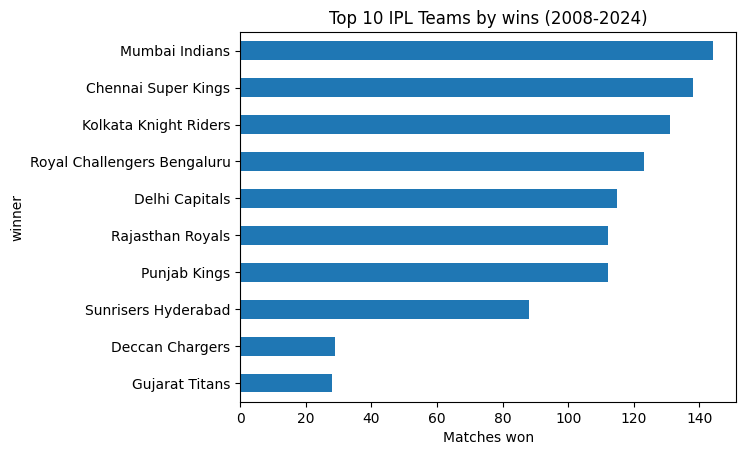

In [141]:
#Count wins,. remove "No result", keep the top 10
wins = df["winner"].value_counts().drop("No result").head(10)
wins.plot(kind="barh")
plt.title("Top 10 IPL Teams by wins (2008-2024)")
plt.xlabel("Matches won")
plt.gca().invert_yaxis()# Most wins at the top
plt.show()


In [142]:
#What teams choose after winnig the the toss
toss_decision =df["toss_decision"].value_counts()
print(toss_decision)
#Keep only matches that had winner
valid_matches = df[df["winner"] != "No result"]
# Calculate the number of times the toss winner also won the match
wins = (valid_matches["toss_winner"]== valid_matches["winner"]).sum()
print(wins)
win_percentage = (wins / len(valid_matches)) * 100
print("win_percentage is :",win_percentage)


toss_decision
field    704
bat      391
Name: count, dtype: int64
554
win_percentage is : 50.825688073394495


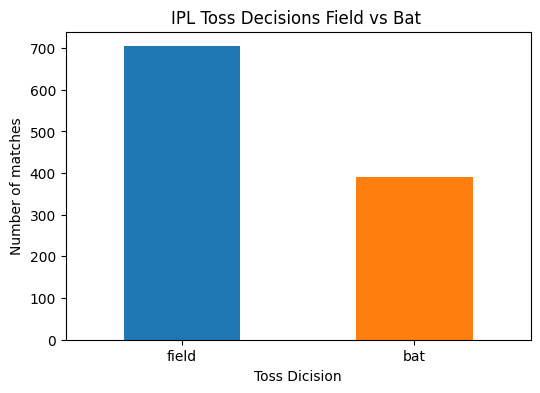

In [143]:
plt.figure(figsize=(6,4))
toss_decision.plot(kind="bar",color=["#1f77b4","#ff7f0e"])
plt.title("IPL Toss Decisions Field vs Bat ")
plt.xlabel("Toss Dicision")
plt.ylabel("Number of matches")
plt.xticks(rotation=0)#Keeps X-axis labels perfectly horizontal for better readable
plt.show()


player_of_match
AB de Villiers    25
CH Gayle          22
RG Sharma         19
V Kohli           18
DA Warner         18
MS Dhoni          17
YK Pathan         16
RA Jadeja         16
SR Watson         16
AD Russell        15
Name: count, dtype: int64


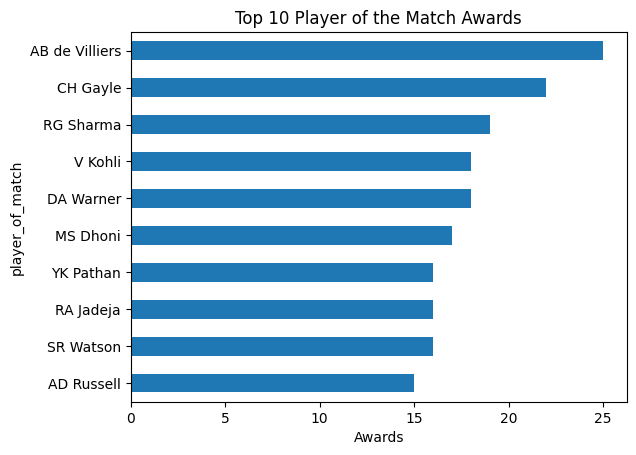

Total Matches Played Per Season: 
season
2007/08    58
2009       57
2009/10    60
2011       73
2012       74
2013       76
2014       60
2015       59
2016       60
2017       59
2018       60
2019       60
2020/21    60
2021       60
2022       74
2023       74
2024       71
Name: count, dtype: int64


In [144]:
#Top 10 Player of the match winners
top_players = df["player_of_match"].value_counts().head(10)
print(top_players)
top_players.plot(kind="barh")
plt.title("Top 10 Player of the Match Awards")
plt.xlabel("Awards")
plt.gca().invert_yaxis()
plt.show()
#Matches in each season
print("Total Matches Played Per Season: ")
matches_per_season = df["season"].value_counts().sort_index()
print(matches_per_season)

## Conclusion
-Mumbai Indians won the most matches (144), followed by  CSK (138) and KKR(131).                                                                           
-Teams chose to field first in 704 matches and bat first in 391.                
-The toss winner won  only about 51% of matches, so the toss gives a very small advantage.                                                               
-AB de Villiiers has the most Player of the Match awards (25),  then CH Gayle (22) and RG Sharma (19).